# Customer Feature Dimensionality Reduction (PCA Project)


### 1. Load Dataset


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", palette="muted")

csv_path = "../csv/customer_pca_data.csv" if os.path.exists("../csv/customer_pca_data.csv") else "csv/customer_pca_data.csv"
df = pd.read_csv(csv_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())


Dataset Shape: (120, 7)

First 5 rows:
   customer_id  annual_income  spending_score  monthly_visits  avg_cart_value  membership_years  segment
0         2001          59383              52               6           68.66               4.4  Regular
1         2002         107610              84              12          149.62               6.9  Premium
2         2003          62258              47               7          102.27               6.3  Regular
3         2004          66396              57               7           60.46               4.0  Regular
4         2005          35361              47               3           43.02               1.5   Budget


### 2. Feature Standardization (Z-Score Scaling)


In [2]:
features = ["annual_income", "spending_score", "monthly_visits", "avg_cart_value", "membership_years"]
X = df[features]

# Standardize features before applying PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Features Mean (approx 0):", np.round(X_scaled.mean(axis=0), 2))
print("Scaled Features Std  (approx 1):", np.round(X_scaled.std(axis=0), 2))


Scaled Features Mean (approx 0): [ 0. -0.  0. -0. -0.]
Scaled Features Std  (approx 1): [1. 1. 1. 1. 1.]


### 3. Fit PCA & Check Explained Variance


In [3]:
pca_full = PCA()
pca_full.fit(X_scaled)

exp_var = pca_full.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

print("Explained Variance Ratio by Component:")
for i in range(len(features)):
    print(f"PC{i+1}: {exp_var[i]:5.2f}% | Cumulative: {cum_var[i]:6.2f}%")


Explained Variance Ratio by Component:
PC1: 88.55% | Cumulative:  88.55%
PC2:  4.90% | Cumulative:  93.45%
PC3:  3.01% | Cumulative:  96.46%
PC4:  2.19% | Cumulative:  98.65%
PC5:  1.35% | Cumulative: 100.00%


### 4. Reduce Dimensions (5D to 2D) & Inspect Feature Loadings


In [4]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=features,
    columns=["PC1", "PC2"]
).round(3)

print(f"Original Shape: {X_scaled.shape} -> Reduced Shape: {X_pca.shape}")
print("\nFeature Loadings (Contribution to PC1 & PC2):\n", loadings)


Original Shape: (120, 5) -> Reduced Shape: (120, 2)

Feature Loadings (Contribution to PC1 & PC2):
                    PC1    PC2
annual_income     0.458 -0.327
spending_score    0.449 -0.051
monthly_visits    0.447 -0.306
avg_cart_value    0.455 -0.145
membership_years  0.426  0.881


### 5. Visualize Scree Plot & 2D PCA Projection


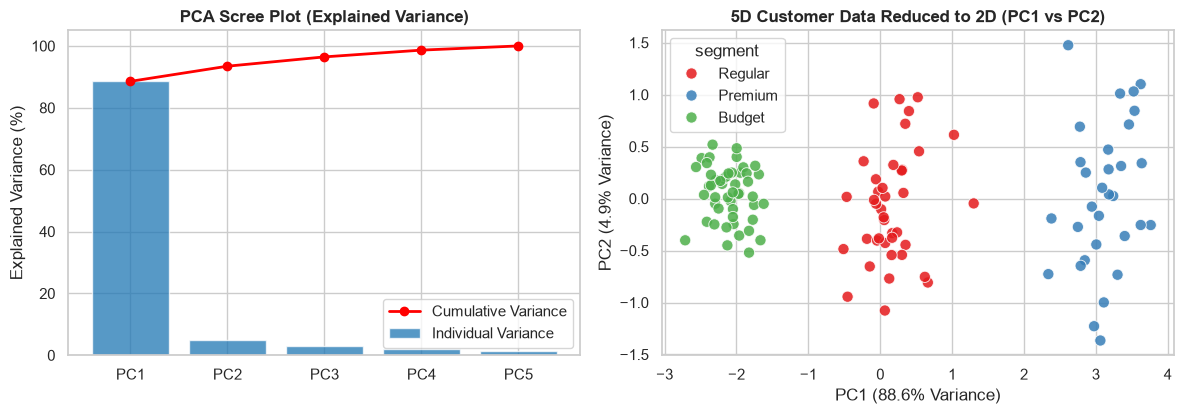

In [5]:
pca_df = pd.DataFrame({
    "customer_id": df["customer_id"],
    "PC1": np.round(X_pca[:, 0], 4),
    "PC2": np.round(X_pca[:, 1], 4),
    "segment": df["segment"]
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# 1. Scree Plot
components_num = np.arange(1, len(features) + 1)
axes[0].bar(components_num, exp_var, alpha=0.75, color="#1f77b4", label="Individual Variance")
axes[0].plot(components_num, cum_var, marker="o", color="red", linewidth=2, label="Cumulative Variance")
axes[0].set_xticks(components_num)
axes[0].set_xticklabels([f"PC{i}" for i in components_num])
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_title("PCA Scree Plot (Explained Variance)", fontsize=12, fontweight="bold")
axes[0].legend()

# 2. 2D Scatter Plot
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue="segment",
    palette="Set1", s=65, alpha=0.85, ax=axes[1]
)
axes[1].set_title("5D Customer Data Reduced to 2D (PC1 vs PC2)", fontsize=12, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({exp_var[0]:.1f}% Variance)")
axes[1].set_ylabel(f"PC2 ({exp_var[1]:.1f}% Variance)")

plt.tight_layout()
plt.show()


### 6. Save Reduced 2D Dataset to CSV


In [6]:
out_dir = "../csv" if os.path.exists("../csv") else "csv"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, "pca_projection.csv")

pca_df.to_csv(out_file, index=False)
print(f"Saved 2D PCA projection to: {out_file}")


Saved 2D PCA projection to: csv\pca_projection.csv
